# Sprint 1 — Notebook 2: tempo de processamento do Pix **depois** da intervenção

**Variável:** `Tempo_processamento_seg` — tempo de processamento de um pagamento via Pix no checkout do e-commerce
**Unidade de medida:** segundos
**Dados:** Planilha 2 — 100 observações coletadas **depois** da inclusão da etapa extra de validação antifraude.

Este notebook responde às Questões 7.1 a 7.4 (Planilha 2) e à Questão 8 (comparação com a Planilha 1), seguindo os comandos do material "Python - Distribuição Normal". A análise da Planilha 1 (Questões 1 a 6) está em `Notebook_1_Analise_Antes_Intervencao.ipynb`.

## 1. Importar as bibliotecas

In [1]:
# Importa o pandas para ler a planilha e manipular os dados em tabela.
import pandas as pd
# Importa o numpy para operações numéricas.
import numpy as np
# Importa o math para funções matemáticas.
import math
# Importa o seaborn para construir o histograma e o boxplot.
import seaborn as sns
# Importa o pyplot do matplotlib para títulos, rótulos e exibição dos gráficos.
import matplotlib.pyplot as plt
# Importa o statsmodels para construir o gráfico Q-Q.
import statsmodels.api as sm
# Importa a distribuição normal (norm) do scipy para probabilidades e quantis.
from scipy.stats import norm
# Importa o pylab para exibir o gráfico Q-Q.
import pylab

## 2. Definir as variáveis `arquivo` e `coluna`

In [2]:
# Define a variável arquivo com o caminho da Planilha 2 (dados depois da intervenção).
arquivo = "../Refs/Planilha 2 -TEMPO PAGAMENTO PIX-2.xlsx"
# Define a variável coluna com o nome da coluna analisada (tempo em segundos).
coluna = "Tempo_processamento_seg"

## 3. Leitura do arquivo de dados — Planilha 2 (depois da intervenção)

In [3]:
# Lê a planilha com pd.read_excel e armazena os dados na variável df.
df=pd.read_excel(arquivo)
# Exibe a tabela armazenada.
df

,Tempo_processamento_seg
0,3.01
1,3.47
2,3.67
3,3.68
4,3.75
...,...
95,6.54
96,6.57
97,6.61
98,6.84


## Questão 7.1 — Formulação da situação, da intervenção e do objetivo

**Situação (problema identificado):** o aumento de tentativas de fraude em pagamentos via Pix levou a área de risco do e-commerce a exigir um controle mais rigoroso. A análise da Planilha 1 mostrou que, antes de qualquer mudança, o processamento era rápido: média de 2,51 segundos, cerca de 89% dos pagamentos em até 3 segundos e 78,85% de probabilidade de ficar na faixa ideal de 2 a 3 segundos. A preocupação é que reforçar a segurança deixe o pagamento lento a ponto de o cliente desistir da compra.

**Ação (intervenção realizada):** a empresa adicionou uma etapa extra de validação antifraude ao fluxo do Pix: antes da confirmação, cada transação passa por uma análise de risco (dados do pagador, dispositivo e histórico de compras). Depois da implantação, foi coletado o tempo de processamento de 100 novos pagamentos, que formam a Planilha 2.

**Objetivo (mudança esperada na variável):** sabe-se que a nova etapa torna o processamento mais lento, então o objetivo não é reduzir o tempo, e sim garantir que o aumento fique controlado, com os pagamentos continuando dentro do limite tolerável de até 6 segundos definido na Questão 1.

**Pergunta de decisão:** com a nova etapa de validação antifraude, o tempo de processamento dos pagamentos via Pix continua aceitável, ou seja, dentro de até 6 segundos, a ponto de a empresa manter a etapa sem prejudicar a experiência de compra?

Resumo: **Situação** — reforço contra fraudes no Pix com risco de lentidão; **Intervenção** — etapa extra de validação antifraude; **Objetivo** — manter o tempo de processamento dentro do aceitável (até 6 segundos).

## Questão 7.2 — Representação gráfica dos dados posteriores à intervenção

### 4.1 Representação do histograma com a curva normal

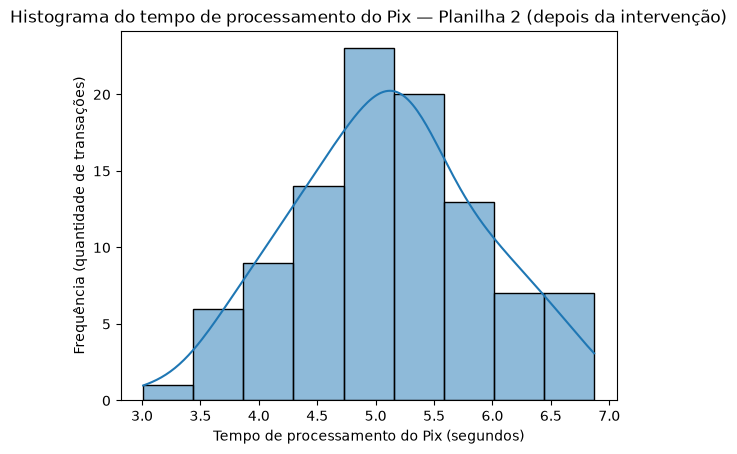

In [4]:
# Plota o histograma com a curva de densidade (kde), como no item 4.1 do material.
sns.histplot(data=df[coluna],kde=True)
# Define o título do gráfico, identificando a variável e o momento da coleta.
plt.title("Histograma do tempo de processamento do Pix — Planilha 2 (depois da intervenção)")
# Identifica a variável e a unidade de medida no eixo x.
plt.xlabel("Tempo de processamento do Pix (segundos)")
# Identifica o eixo y como a frequência (quantidade de transações).
plt.ylabel("Frequência (quantidade de transações)")
# Exibe o gráfico.
plt.show()

### 4.2 Boxplot

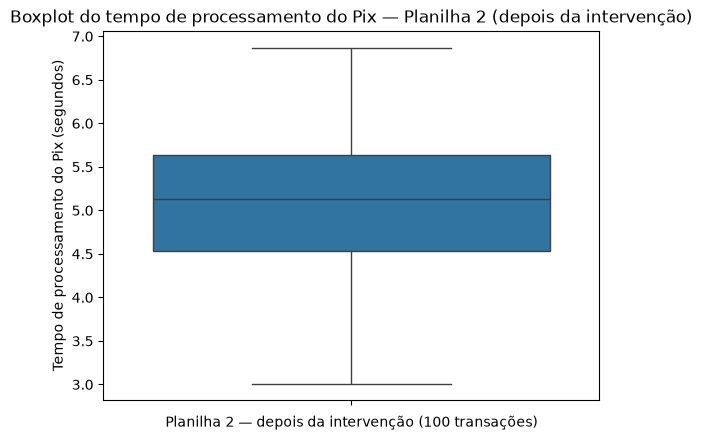

In [5]:
# Plota o boxplot, como no item 4.2 do material.
sns.boxplot(data=df[coluna])
# Define o título do gráfico, identificando a variável e o momento da coleta.
plt.title("Boxplot do tempo de processamento do Pix — Planilha 2 (depois da intervenção)")
# Identifica no eixo x a planilha representada.
plt.xlabel("Planilha 2 — depois da intervenção (100 transações)")
# Identifica a variável e a unidade de medida no eixo y.
plt.ylabel("Tempo de processamento do Pix (segundos)")
# Exibe o gráfico.
plt.show()

**Interpretação breve:** Depois da etapa antifraude, o histograma passou a se concentrar perto de 5 segundos, com valores entre cerca de 3 e 6,9 segundos, e mantém um único pico com formato de sino. O boxplot é aproximadamente simétrico, com a caixa (50% centrais) entre cerca de 4,5 e 5,6 segundos. Visualmente, todo o conjunto se deslocou para tempos maiores e ficou mais espalhado do que na Planilha 1, e parte das transações passa do limite tolerável de 6 segundos.

## Questão 7.3 — Média e desvio-padrão dos dados posteriores à intervenção

### 5. Cálculo da Média, Mediana e do Desvio Padrão

#### Média

In [6]:
# mean -> calcula a média aritmética dos tempos (arredondada em 2 casas).
media = round(df[coluna].mean(), 2)
# Mostra a média com a unidade de medida.
print(f'Média depois da intervenção: {media} segundos')

Média depois da intervenção: 5.1 segundos


#### Mediana

In [7]:
# median -> calcula a mediana (valor central dos tempos ordenados).
mediana = round(df[coluna].median(), 2)
# Mostra a mediana com a unidade de medida.
print(f'Mediana depois da intervenção: {mediana} segundos')

Mediana depois da intervenção: 5.12 segundos


#### Desvio-padrão amostral

In [8]:
# std -> calcula o desvio-padrão amostral (divisor n - 1), arredondado em 2 casas.
dpad = round(df[coluna].std(), 2)
# Mostra o desvio-padrão com a unidade de medida.
print(f'Desvio-padrão depois da intervenção: {dpad} segundos')

Desvio-padrão depois da intervenção: 0.81 segundos


**Interpretação breve:** Depois da intervenção, a média do tempo de processamento é de 5,10 segundos e o desvio-padrão é de 0,81 segundo. A média ficou próxima do dobro da registrada na Planilha 1 (2,51 segundos) e a variabilidade também aumentou (o desvio-padrão era de 0,40 segundo), o que indica que a nova etapa acrescenta tempo e deixa o processamento menos uniforme.

## Questão 7.4 — Análise de um intervalo relacionado ao objetivo

**Intervalo escolhido:** de 0 a 6 segundos, ou seja, pagamentos processados em até 6 segundos.

**Justificativa:** o objetivo da Questão 7.1 é manter o tempo dentro do limite tolerável de 6 segundos definido na Questão 1; por isso o intervalo que interessa à decisão é o dos pagamentos que respeitam esse limite.

**Pergunta:** quantas das 100 transações da Planilha 2, realizadas depois da etapa antifraude, foram processadas em até 6 segundos?

In [9]:
# Define o limite tolerável de tempo de processamento, em segundos (Questão 1).
limite_tolerancia_segundos = 6.0
# Conta os tempos no intervalo de 0 a 6 segundos (mesma lógica de contagem do item 6.1.2).
quantidade_intervalo_depois=sum(i>=0 and i<= limite_tolerancia_segundos for i in df[coluna].sort_values())
# Conta, como complemento, os tempos na faixa ideal de 2 a 3 segundos.
quantidade_faixa_ideal_depois=sum(i>=2 and i<= 3 for i in df[coluna].sort_values())
# Mostra a quantidade de transações dentro do limite tolerável.
print(f'Transações com até 6 segundos: {quantidade_intervalo_depois} de {len(df[coluna])}')
# Mostra a quantidade de transações na faixa ideal.
print(f'Transações entre 2 e 3 segundos: {quantidade_faixa_ideal_depois} de {len(df[coluna])}')

Transações com até 6 segundos: 85 de 100
Transações entre 2 e 3 segundos: 0 de 100


**Interpretação breve:** Das 100 transações coletadas depois da etapa antifraude, 85 de 100 foram processadas em até 6 segundos, ou seja, 15 ultrapassaram o limite tolerável. Nenhuma transação ficou na faixa ideal de 2 a 3 segundos. Assim, a maior parte dos pagamentos continua aceitável, mas a experiência de pagamento instantâneo deixou de existir e uma parcela relevante passou a ter espera acima do tolerável.

## Questão 8 — Comparação entre os resultados

Análise preliminar e descritiva; as ferramentas de inferência estatística serão aplicadas na Sprint 2.

**Pergunta:** com base neste estudo, há indícios de que a etapa extra de validação antifraude mudou o tempo de processamento dos pagamentos via Pix e, mesmo assim, o manteve dentro do aceitável?

**Critério 1 — faixa ideal:** comparação entre as proporções de pagamentos processados em até 3 segundos, teto da faixa ideal de pagamento instantâneo. Mede quanto a intervenção afetou a experiência ideal.

**Critério 2 — limite tolerável:** comparação entre as proporções de pagamentos processados em até 6 segundos, limite tolerável definido na Questão 1 e usado no objetivo da Questão 7.1. Mede se o tempo continua aceitável depois da intervenção.

Para comparar, a Planilha 1 é lida novamente apenas nesta seção, na variável `df_antes`.

In [10]:
# Define o caminho da Planilha 1, usada só para a comparação.
arquivo_antes = "../Refs/Planilha 1 - TEMPO PAGAMENTO PIX.xlsx"
# Lê a Planilha 1 e armazena os dados antes da intervenção.
df_antes=pd.read_excel(arquivo_antes)
# Calcula a média da Planilha 1, em segundos.
media_antes = round(df_antes[coluna].mean(), 2)
# Calcula o desvio-padrão amostral da Planilha 1, em segundos.
dpad_antes = round(df_antes[coluna].std(), 2)
# Mostra os valores de referência do cenário antes da intervenção.
print(f'Planilha 1: {len(df_antes)} observações | média {media_antes} segundos | desvio-padrão {dpad_antes} segundos')

Planilha 1: 300 observações | média 2.51 segundos | desvio-padrão 0.4 segundos


In [11]:
# Define o teto da faixa ideal, em segundos (Critério 1).
limite_ideal_segundos = 3.0
# Proporção de pagamentos em até 3 segundos antes da intervenção.
proporcao_criterio_1_antes = sum(i<= limite_ideal_segundos for i in df_antes[coluna])/len(df_antes[coluna])
# Proporção de pagamentos em até 3 segundos depois da intervenção.
proporcao_criterio_1_depois = sum(i<= limite_ideal_segundos for i in df[coluna])/len(df[coluna])
# Proporção de pagamentos em até 6 segundos antes da intervenção (Critério 2).
proporcao_criterio_2_antes = sum(i<= limite_tolerancia_segundos for i in df_antes[coluna])/len(df_antes[coluna])
# Proporção de pagamentos em até 6 segundos depois da intervenção.
proporcao_criterio_2_depois = sum(i<= limite_tolerancia_segundos for i in df[coluna])/len(df[coluna])
# Monta uma tabela comparativa entre os dois cenários.
tabela_comparacao = pd.DataFrame(
    {
        "Critério": [
            "Critério 1: até 3 segundos (ideal)",
            "Critério 2: até 6 segundos (tolerável)",
            "Média do tempo",
            "Desvio-padrão do tempo",
        ],
        "Unidade": ["% das transações", "% das transações", "segundos", "segundos"],
        "Antes (Planilha 1)": [
            f"{proporcao_criterio_1_antes:.1%}",
            f"{proporcao_criterio_2_antes:.1%}",
            f"{media_antes:.2f}",
            f"{dpad_antes:.2f}",
        ],
        "Depois (Planilha 2)": [
            f"{proporcao_criterio_1_depois:.1%}",
            f"{proporcao_criterio_2_depois:.1%}",
            f"{media:.2f}",
            f"{dpad:.2f}",
        ],
    }
)
# Exibe a tabela sem o índice numérico.
print(tabela_comparacao.to_string(index=False))

                              Critério          Unidade Antes (Planilha 1) Depois (Planilha 2)
    Critério 1: até 3 segundos (ideal) % das transações              89.0%                0.0%
Critério 2: até 6 segundos (tolerável) % das transações             100.0%               85.0%
                        Média do tempo         segundos               2.51                5.10
                Desvio-padrão do tempo         segundos               0.40                0.81


**Interpretação breve:** Pelo Critério 1, a proporção de pagamentos em até 3 segundos caiu de 89% para 0%: a faixa ideal de pagamento instantâneo deixou de ser atingida. Pelo Critério 2, a proporção de pagamentos em até 6 segundos passou de 100% para 85%: a maioria continua dentro do tolerável, mas 15% das transações passaram a exceder esse limite.

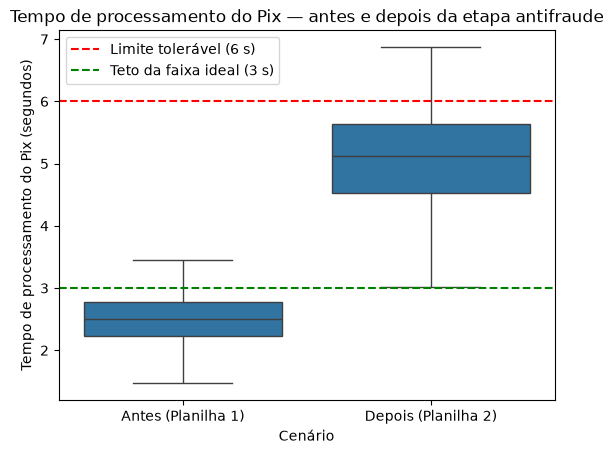

In [12]:
# Junta os dois cenários em uma tabela, identificando a planilha de origem.
dados_comparacao = pd.concat(
    [
        pd.DataFrame({"Cenário": "Antes (Planilha 1)", coluna: df_antes[coluna]}),
        pd.DataFrame({"Cenário": "Depois (Planilha 2)", coluna: df[coluna]}),
    ]
)
# Plota os boxplots lado a lado para comparar visualmente os dois cenários.
sns.boxplot(data=dados_comparacao, x="Cenário", y=coluna)
# Desenha a linha do limite tolerável de 6 segundos.
plt.axhline(limite_tolerancia_segundos, color="red", linestyle="--", label="Limite tolerável (6 s)")
# Desenha a linha do teto da faixa ideal de 3 segundos.
plt.axhline(limite_ideal_segundos, color="green", linestyle="--", label="Teto da faixa ideal (3 s)")
# Define o título do gráfico comparativo.
plt.title("Tempo de processamento do Pix — antes e depois da etapa antifraude")
# Identifica o eixo x.
plt.xlabel("Cenário")
# Identifica a variável e a unidade de medida no eixo y.
plt.ylabel("Tempo de processamento do Pix (segundos)")
# Mostra a legenda das linhas de referência.
plt.legend()
# Exibe o gráfico.
plt.show()

In [13]:
# Calcula a diferença entre as médias (depois - antes), em segundos.
diferenca_media_segundos = round(media - media_antes, 2)
# Mostra a diferença descritiva entre as médias.
print(f'Diferença entre as médias (depois - antes): {diferenca_media_segundos:+.2f} segundos')
# Verifica o sentido da mudança para descrever o resultado corretamente.
if diferenca_media_segundos > 0:
    # Descreve o aumento do tempo médio.
    print(f'Na amostra, a média depois foi {diferenca_media_segundos:.2f} segundos maior: o processamento ficou mais lento.')
elif diferenca_media_segundos < 0:
    # Descreve a redução do tempo médio.
    print(f'Na amostra, a média depois foi {abs(diferenca_media_segundos):.2f} segundos menor: o processamento ficou mais rápido.')
else:
    # Descreve o caso de médias iguais.
    print('As médias observadas antes e depois foram iguais.')
# Lembra que a comparação é apenas descritiva.
print('Esta comparação descritiva entre amostras não comprova causalidade; a inferência será feita na Sprint 2.')

Diferença entre as médias (depois - antes): +2.59 segundos
Na amostra, a média depois foi 2.59 segundos maior: o processamento ficou mais lento.
Esta comparação descritiva entre amostras não comprova causalidade; a inferência será feita na Sprint 2.


**Interpretação breve:** A média subiu de 2,51 para 5,10 segundos, um aumento de +2,59 segundos, e o desvio-padrão dobrou. Combinando os dois critérios — queda de 89% para 0% na faixa ideal e de 100% para 85% dentro do limite tolerável — há indícios de que a etapa antifraude tornou o processamento do Pix mais lento e de que o tempo **continua aceitável para a maioria** dos pagamentos, mas não para todos: cerca de 15% excedem 6 segundos. Conclusão preliminar: a etapa pode ser mantida, com ressalvas, e a empresa deve buscar otimizações para reduzir a cauda acima de 6 segundos. Por ser uma comparação descritiva entre amostras, ela não demonstra causalidade; a confirmação será feita com inferência estatística na Sprint 2.